<a href="https://colab.research.google.com/github/DobryCzlowiekDobryKodzik/Traffic-Sign-Recognition/blob/main/notebooks/etap_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Etap 2 – Implementacja potoku przetwarzania obrazów

## 1. Wczytywanie danych

W pierwszym kroku przygotowano mechanizm automatycznego wczytywania zdjęć znaków drogowych z Dysku Google. Zdjęcia zostały podzielone na foldery odpowiadające rozpoznawanym znakom oraz pozostałym znakom drogowym.

In [6]:
from google.colab import drive
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

drive.mount('/content/drive')

Mounted at /content/drive


In [7]:

DATA_DIR = Path('/content/drive/MyDrive/Zdjęcia-projekt')

In [9]:
# Etykiety rozpoznawanych znaków
klasy = {
    "stop": "B-20",
    "rondo": "C-12",
    "skrzyzowanie": "A-5",
    "inne": "Inny znak"
}

rozszerzenia = {".jpg", ".jpeg", ".png"}
dane = []

for folder, etykieta in klasy.items():
    sciezka_folderu = DATA_DIR / folder

    if not sciezka_folderu.exists():
        print(f"Brak folderu: {sciezka_folderu}")
        continue

    for plik in sorted(sciezka_folderu.rglob("*")):
        if plik.suffix.lower() not in rozszerzenia:
            continue

        obraz = cv2.imread(str(plik))

        if obraz is None:
            print(f"Nie udało się wczytać: {plik.name}")
            continue

        dane.append({
            "plik": plik.name,
            "sciezka": str(plik),
            "etykieta": etykieta,
            "szerokosc": obraz.shape[1],
            "wysokosc": obraz.shape[0]
        })

df_zdjecia = pd.DataFrame(dane)

print(f"Wczytano {len(df_zdjecia)} zdjęć.")
display(df_zdjecia)

Wczytano 9 zdjęć.


,plik,sciezka,etykieta,szerokosc,wysokosc
0,20261030_115146.jpg,/content/drive/MyDrive/Zdjęcia-projekt/stop/20...,B-20,6000,8000
1,20261030_115203.jpg,/content/drive/MyDrive/Zdjęcia-projekt/stop/20...,B-20,6000,8000
2,20261030_115314.jpg,/content/drive/MyDrive/Zdjęcia-projekt/stop/20...,B-20,6000,8000
3,20261030_115838.jpg,/content/drive/MyDrive/Zdjęcia-projekt/rondo/2...,C-12,6000,8000
4,20261030_115905.jpg,/content/drive/MyDrive/Zdjęcia-projekt/rondo/2...,C-12,6000,8000
5,20261030_115950.jpg,/content/drive/MyDrive/Zdjęcia-projekt/rondo/2...,C-12,6000,8000
6,20261030_114244.jpg,/content/drive/MyDrive/Zdjęcia-projekt/skrzyzo...,A-5,6000,8000
7,20261030_114303.jpg,/content/drive/MyDrive/Zdjęcia-projekt/skrzyzo...,A-5,6000,8000
8,20261030_114458.jpg,/content/drive/MyDrive/Zdjęcia-projekt/skrzyzo...,A-5,6000,8000


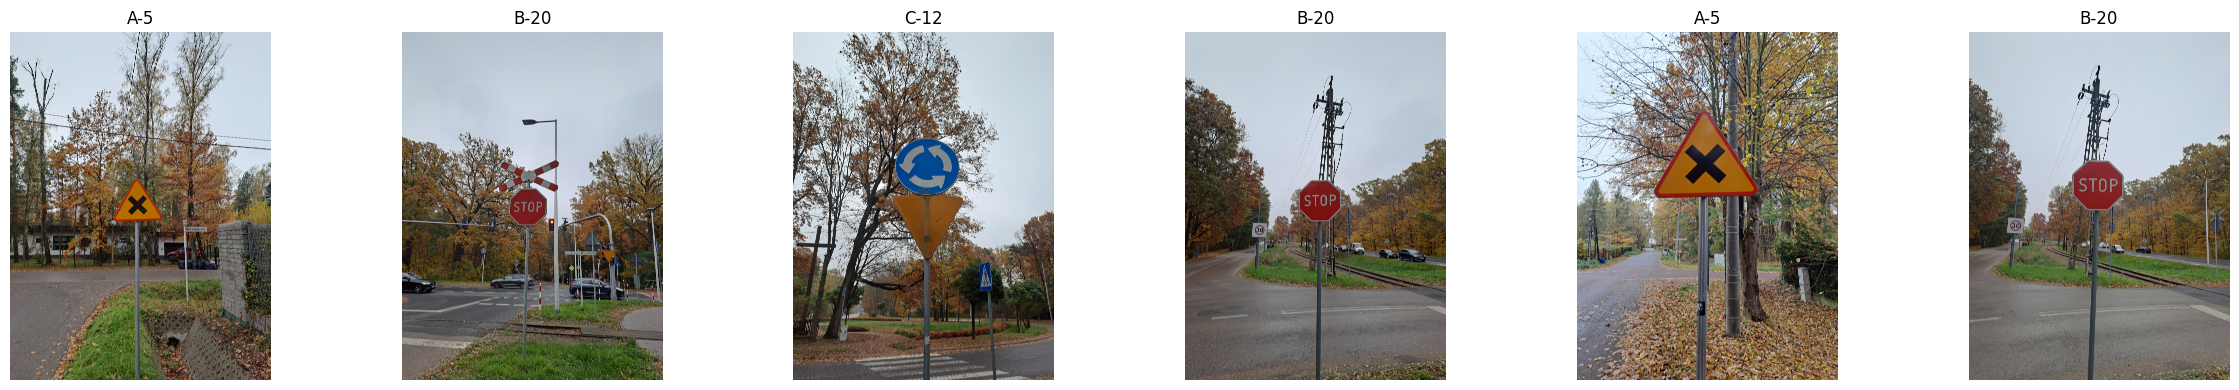

In [10]:
if len(df_zdjecia) > 0:
    probka = df_zdjecia.sample(
        n=min(6, len(df_zdjecia)),
        random_state=42
    )

    fig, axes = plt.subplots(
        1, len(probka),
        figsize=(4 * len(probka), 4),
        squeeze=False
    )

    for ax, (_, wiersz) in zip(axes[0], probka.iterrows()):
        obraz = cv2.imread(wiersz["sciezka"])
        obraz_rgb = cv2.cvtColor(obraz, cv2.COLOR_BGR2RGB)

        ax.imshow(obraz_rgb)
        ax.set_title(wiersz["etykieta"])
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Nie znaleziono zdjęć. Sprawdź ścieżkę DATA_DIR.")

## 2. Przetwarzanie wstępne obrazów

Celem przetwarzania wstępnego jest przygotowanie obrazów do dalszej segmentacji i ekstrakcji cech znaków drogowych. Zastosowano następujące operacje:

1. **Skalowanie proporcjonalne** – zmniejszenie rozdzielczości obrazów z zachowaniem ich oryginalnych proporcji. Maksymalny wymiar obrazu ustalono na 800 pikseli.
2. **Filtracja Gaussa** – zastosowanie filtra o rozmiarze 5×5 w celu redukcji szumów i niewielkich zakłóceń obrazu.
3. **Korekcja kontrastu CLAHE (opcjonalnie)** – lokalne wyrównanie kontrastu w kanale jasności przestrzeni Lab, poprawiające widoczność szczegółów w nierównomiernych warunkach oświetlenia.

Zastosowanie CLAHE będzie oceniane na podstawie porównania wyników przetwarzania i segmentacji obrazów.

In [12]:
def skaluj_proporcjonalnie(obraz, max_wymiar=800):
    h, w = obraz.shape[:2]

    # Zachowanie proporcji i unikanie powiększania małych obrazów
    skala = min(max_wymiar / max(h, w), 1.0)

    nowa_szerokosc = max(1, int(round(w * skala)))
    nowa_wysokosc = max(1, int(round(h * skala)))

    return cv2.resize(
        obraz,
        (nowa_szerokosc, nowa_wysokosc),
        interpolation=cv2.INTER_AREA
    )


def przetwarzanie_wstepne(obraz, uzyj_clahe=False):
    # 1. Skalowanie proporcjonalne
    obraz = skaluj_proporcjonalnie(obraz)

    # 2. Filtr Gaussa 5x5
    obraz = cv2.GaussianBlur(obraz, (5, 5), 0)

    # 3. Opcjonalna korekcja kontrastu CLAHE
    if uzyj_clahe:
        lab = cv2.cvtColor(obraz, cv2.COLOR_BGR2LAB)
        l, a, b = cv2.split(lab)

        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )

        l = clahe.apply(l)

        lab = cv2.merge((l, a, b))
        obraz = cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

    return obraz

In [20]:
przetworzone = []
for _,i in df_zdjecia.iterrows():
  obraz = cv2.imread(i["sciezka"])
  obraz = przetwarzanie_wstepne(obraz)
  przetworzone.append(obraz)


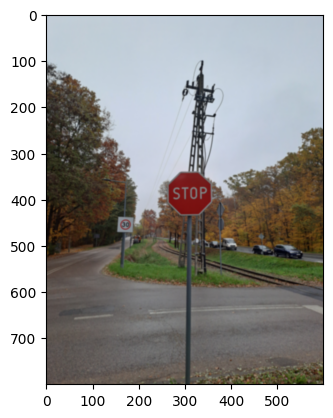

In [22]:
plt.imshow(cv2.cvtColor(przetworzone[0], cv2.COLOR_BGR2RGB))